In [4]:
# ============================================================
# Cell 1: Imports & Environment Check
# ============================================================
import os
import re
import json
import random
from collections import Counter
from dataclasses import dataclass, field, asdict

import numpy as np
import pandas as pd
import tensorflow as tf
import keras

print(f"TensorFlow: {tf.__version__} | Keras: {keras.__version__}")

# Allocate GPU memory on demand instead of grabbing it all at once
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print("Memory growth must be set before GPUs are initialized:", e)
print(f"GPUs available: {len(gpus)} -> {gpus}")

TensorFlow: 2.21.0 | Keras: 3.13.2
GPUs available: 2 -> [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [5]:
# ============================================================
# Cell 2: Discover dataset paths under /kaggle/input
# ============================================================
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.replace("/kaggle/input", "").count(os.sep)
    if depth > 3:
        continue
    indent = "  " * depth
    print(f"{indent}{os.path.basename(root)}/  ({len(files)} files)")
    for f in files[:3]:
        if not f.lower().endswith((".jpg", ".jpeg", ".png")):
            print(f"{indent}  - {f}")

input/  (0 files)
  datasets/  (0 files)
    eeshawn/  (0 files)
      flickr30k/  (1 files)
        - captions.txt
    adityajn105/  (0 files)
      flickr8k/  (1 files)
        - captions.txt


In [6]:
# ============================================================
# Cell 3: Central Configuration
# ============================================================
# Update these paths to match the output of Cell 2.
DATASET_REGISTRY = {
    "flickr8k": {
        "image_dir": "/kaggle/input/datasets/adityajn105/flickr8k/Images",
        "captions_file": "/kaggle/input/datasets/adityajn105/flickr8k/captions.txt",
        "num_val_images": 1000,
        "num_test_images": 1000,
        "min_word_freq": 5,
    },
    "flickr30k": {
        "image_dir": "/kaggle/input/datasets/eeshawn/flickr30k/flickr30k_images",
        "captions_file": "/kaggle/input/datasets/eeshawn/flickr30k/captions.txt",
        "num_val_images": 1000,
        "num_test_images": 1000,
        "min_word_freq": 5,
    },
}


@dataclass
class Config:
    # ---- Switch dataset here: "flickr8k" (Phase 1) or "flickr30k" (Phase 2)
    DATASET: str = "flickr30k"
    SEED: int = 42

    # ---- Output paths
    WORK_DIR: str = "/kaggle/working"
    SAVE_DIR: str = "/kaggle/working/saved_models"
    DATA_DIR: str = "/kaggle/working/data"

    # ---- Text / vocabulary
    MAX_LEN: int = 0                    # 0 = auto-detect from training captions
    CAPTION_LEN_PERCENTILE: float = 98.0

    # ---- Image encoder (EfficientNetB3 native resolution)
    IMAGE_SIZE: int = 300

    # ---- Transformer decoder (used in Milestone 3)
    EMBED_DIM: int = 512
    NUM_HEADS: int = 8
    FF_DIM: int = 2048
    NUM_DECODER_LAYERS: int = 3
    DROPOUT: float = 0.3

    # ---- Training (used in Milestone 3)
    BATCH_SIZE: int = 64
    EPOCHS: int = 20
    LEARNING_RATE: float = 3e-4
    WEIGHT_DECAY: float = 1e-4
    EARLY_STOPPING_PATIENCE: int = 4

    # ---- Inference (used in Milestone 4)
    BEAM_WIDTH: int = 3
    
    FEATURE_DIR: str = "/tmp/features"     # ephemeral disk, does not count against /kaggle/working output
    EXTRACT_BATCH_SIZE: int = 32

    # ---- Filled automatically from DATASET_REGISTRY
    IMAGE_DIR: str = field(init=False, default="")
    CAPTIONS_FILE: str = field(init=False, default="")
    NUM_VAL_IMAGES: int = field(init=False, default=0)
    NUM_TEST_IMAGES: int = field(init=False, default=0)
    MIN_WORD_FREQ: int = field(init=False, default=0)

    def __post_init__(self):
        if self.DATASET not in DATASET_REGISTRY:
            raise ValueError(f"Unknown dataset '{self.DATASET}'. "
                             f"Choose from {list(DATASET_REGISTRY)}")
        spec = DATASET_REGISTRY[self.DATASET]
        self.IMAGE_DIR = spec["image_dir"]
        self.CAPTIONS_FILE = spec["captions_file"]
        self.NUM_VAL_IMAGES = spec["num_val_images"]
        self.NUM_TEST_IMAGES = spec["num_test_images"]
        self.MIN_WORD_FREQ = spec["min_word_freq"]
        os.makedirs(self.SAVE_DIR, exist_ok=True)
        os.makedirs(self.DATA_DIR, exist_ok=True)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


cfg = Config()
set_seed(cfg.SEED)

assert os.path.isdir(cfg.IMAGE_DIR), f"Image dir not found: {cfg.IMAGE_DIR}"
assert os.path.isfile(cfg.CAPTIONS_FILE), f"Captions file not found: {cfg.CAPTIONS_FILE}"
print(f"Active dataset: {cfg.DATASET}")
print(f"Images:   {cfg.IMAGE_DIR}")
print(f"Captions: {cfg.CAPTIONS_FILE}")

Active dataset: flickr30k
Images:   /kaggle/input/datasets/eeshawn/flickr30k/flickr30k_images
Captions: /kaggle/input/datasets/eeshawn/flickr30k/captions.txt


In [7]:
# ============================================================
# Cell 4: Robust Caption Loader (supports ',' and '|' formats)
# ============================================================
def load_captions(captions_file: str, image_dir: str) -> pd.DataFrame:
    """
    Parse caption files of the form:
        image,caption                         (Flickr8k / Flickr30k by adityajn105)
        image_name| comment_number| comment   (Flickr30k results.csv variant)
    Splits only on the FIRST separator so commas inside captions are preserved.
    """
    rows = []
    with open(captions_file, encoding="utf-8") as f:
        header = f.readline()
        sep = "|" if "|" in header else ","
        for line in f:
            line = line.strip()
            if not line:
                continue
            if sep == "|":
                parts = [p.strip() for p in line.split("|")]
                if len(parts) < 3:
                    continue
                image, caption = parts[0], "|".join(parts[2:])
            else:
                image, _, caption = line.partition(",")
            image, caption = image.strip(), caption.strip().strip('"')
            if image and caption:
                rows.append((image, caption))

    df = pd.DataFrame(rows, columns=["image", "caption"])

    # Keep only captions whose image file actually exists
    available = set(os.listdir(image_dir))
    before = len(df)
    df = df[df["image"].isin(available)].reset_index(drop=True)
    print(f"Separator: '{sep}' | captions: {before} -> {len(df)} "
          f"(dropped {before - len(df)} with missing images)")
    return df


raw_df = load_captions(cfg.CAPTIONS_FILE, cfg.IMAGE_DIR)
print(f"Unique images: {raw_df['image'].nunique()}")
print(f"Captions per image: {raw_df.groupby('image').size().describe()[['mean', 'min', 'max']].to_dict()}")
raw_df.head()

Separator: ',' | captions: 158915 -> 158915 (dropped 0 with missing images)
Unique images: 31783
Captions per image: {'mean': 5.0, 'min': 5.0, 'max': 5.0}


,image,caption
0,1000092795.jpg,"0,Two young guys with shaggy hair look at thei..."
1,1000092795.jpg,"1,Two young White males are outside near many..."
2,1000092795.jpg,"2,Two men in green shirts are standing in a ya..."
3,1000092795.jpg,"3,A man in a blue shirt standing in a garden ."
4,1000092795.jpg,"4,Two friends enjoy time spent together ."


In [8]:
# ============================================================
# Cell 5: Caption Cleaning
# ============================================================
KEEP_SINGLE_CHARS = {"a", "i"}

def clean_caption(text: str) -> str:
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)          # remove punctuation & digits
    tokens = [t for t in text.split() if len(t) > 1 or t in KEEP_SINGLE_CHARS]
    return " ".join(tokens)


raw_df["clean"] = raw_df["caption"].apply(clean_caption)
raw_df = raw_df[raw_df["clean"].str.len() > 0].reset_index(drop=True)

for orig, cln in raw_df[["caption", "clean"]].sample(3, random_state=cfg.SEED).values:
    print(f"RAW  : {orig}\nCLEAN: {cln}\n")

RAW  : 2,A man is sitting on an upturned white bucket playing a banjo .
CLEAN: a man is sitting on an upturned white bucket playing a banjo

RAW  : 0,Spelunkers pose inside a rock cavern while bathed in sunlight from the surface .
CLEAN: spelunkers pose inside a rock cavern while bathed in sunlight from the surface

RAW  : 4,A toddler enjoying her birthday cake .
CLEAN: a toddler enjoying her birthday cake



In [9]:
# ============================================================
# Cell 6: Leakage-free split (by IMAGE, not by caption)
# ============================================================
def split_by_image(df: pd.DataFrame, n_val: int, n_test: int, seed: int):
    images = sorted(df["image"].unique())
    random.Random(seed).shuffle(images)

    test_imgs = set(images[:n_test])
    val_imgs = set(images[n_test:n_test + n_val])
    train_imgs = set(images[n_test + n_val:])

    train = df[df["image"].isin(train_imgs)].reset_index(drop=True)
    val = df[df["image"].isin(val_imgs)].reset_index(drop=True)
    test = df[df["image"].isin(test_imgs)].reset_index(drop=True)

    assert train_imgs.isdisjoint(val_imgs) and train_imgs.isdisjoint(test_imgs)
    return train, val, test


train_df, val_df, test_df = split_by_image(
    raw_df, cfg.NUM_VAL_IMAGES, cfg.NUM_TEST_IMAGES, cfg.SEED
)
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {d['image'].nunique():6d} images | {len(d):7d} captions")

train:  29783 images |  148915 captions
val  :   1000 images |    5000 captions
test :   1000 images |    5000 captions


In [10]:
# ============================================================
# Cell 7: Vocabulary (framework-agnostic, JSON-serializable)
# ============================================================
class Vocabulary:
    PAD, START, END, UNK = "<pad>", "<start>", "<end>", "<unk>"
    SPECIAL_TOKENS = [PAD, START, END, UNK]     # PAD must be index 0 (for masking)

    def __init__(self, idx2word: list, max_len: int):
        self.idx2word = idx2word
        self.word2idx = {w: i for i, w in enumerate(idx2word)}
        self.max_len = max_len
        self.pad_id = self.word2idx[self.PAD]
        self.start_id = self.word2idx[self.START]
        self.end_id = self.word2idx[self.END]
        self.unk_id = self.word2idx[self.UNK]

    def __len__(self) -> int:
        return len(self.idx2word)

    @classmethod
    def build(cls, captions, min_freq: int, max_len: int) -> "Vocabulary":
        counter = Counter(w for c in captions for w in c.split())
        # Sort by frequency (desc), then alphabetically -> deterministic indices
        words = sorted(
            (w for w, c in counter.items() if c >= min_freq),
            key=lambda w: (-counter[w], w),
        )
        return cls(cls.SPECIAL_TOKENS + words, max_len)

    def encode(self, caption: str) -> list:
        """'a dog runs' -> [<start>, a, dog, runs, <end>, <pad>, ...] as ids (len = max_len)."""
        ids = [self.word2idx.get(w, self.unk_id) for w in caption.split()]
        ids = [self.start_id] + ids[: self.max_len - 2] + [self.end_id]
        return ids + [self.pad_id] * (self.max_len - len(ids))

    def decode(self, ids) -> str:
        words = []
        for i in ids:
            i = int(i)
            if i == self.end_id:
                break
            if i in (self.pad_id, self.start_id):
                continue
            words.append(self.idx2word[i])
        return " ".join(words)

    def save(self, path: str) -> None:
        with open(path, "w", encoding="utf-8") as f:
            json.dump({
                "idx2word": self.idx2word,
                "max_len": self.max_len,
                "special_tokens": {
                    "pad": self.PAD, "start": self.START,
                    "end": self.END, "unk": self.UNK,
                },
            }, f, ensure_ascii=False, indent=2)

    @classmethod
    def load(cls, path: str) -> "Vocabulary":
        with open(path, encoding="utf-8") as f:
            data = json.load(f)
        return cls(data["idx2word"], data["max_len"])

In [11]:
# ============================================================
# Cell 8: Build vocab (train only), auto MAX_LEN, encode all splits
# ============================================================
train_lengths = train_df["clean"].str.split().str.len().to_numpy()
auto_max_len = int(np.percentile(train_lengths, cfg.CAPTION_LEN_PERCENTILE)) + 2  # +2 for <start>/<end>
cfg.MAX_LEN = cfg.MAX_LEN or auto_max_len

print(f"Caption length (words): mean={train_lengths.mean():.1f}, "
      f"max={train_lengths.max()}, p{cfg.CAPTION_LEN_PERCENTILE:.0f}={auto_max_len - 2}")
print(f"MAX_LEN (incl. special tokens) = {cfg.MAX_LEN}")

vocab = Vocabulary.build(train_df["clean"], cfg.MIN_WORD_FREQ, cfg.MAX_LEN)
print(f"Vocabulary size: {len(vocab)} (min_freq={cfg.MIN_WORD_FREQ})")


def encode_split(df: pd.DataFrame) -> np.ndarray:
    return np.asarray([vocab.encode(c) for c in df["clean"]], dtype=np.int32)


train_seqs = encode_split(train_df)
val_seqs = encode_split(val_df)
test_seqs = encode_split(test_df)
print(f"Encoded shapes -> train {train_seqs.shape}, val {val_seqs.shape}, test {test_seqs.shape}")
print(f"RAM used by sequences: {(train_seqs.nbytes + val_seqs.nbytes + test_seqs.nbytes) / 1e6:.1f} MB")

Caption length (words): mean=12.3, max=78, p98=26
MAX_LEN (incl. special tokens) = 28
Vocabulary size: 7388 (min_freq=5)
Encoded shapes -> train (148915, 28), val (5000, 28), test (5000, 28)
RAM used by sequences: 17.8 MB


In [12]:
# ============================================================
# Cell 9: Sanity checks & save artifacts
# ============================================================
# 1) Round-trip check
sample = train_df["clean"].iloc[0]
ids = vocab.encode(sample)
print("Original :", sample)
print("Encoded  :", ids)
print("Decoded  :", vocab.decode(ids))

# 2) Unknown-token rate on validation (should be low, ~1-3%)
val_tokens = val_seqs[(val_seqs != vocab.pad_id) &
                      (val_seqs != vocab.start_id) &
                      (val_seqs != vocab.end_id)]
print(f"<unk> rate on val: {(val_tokens == vocab.unk_id).mean() * 100:.2f}%")

# 3) Save vocab, config and splits
vocab_path = os.path.join(cfg.SAVE_DIR, "vocab.json")
config_path = os.path.join(cfg.SAVE_DIR, "config.json")
vocab.save(vocab_path)
with open(config_path, "w") as f:
    json.dump(asdict(cfg), f, indent=2)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d[["image", "clean"]].to_csv(
        os.path.join(cfg.DATA_DIR, f"{cfg.DATASET}_{name}.csv"), index=False
    )

# 4) Reload test
assert Vocabulary.load(vocab_path).encode(sample) == ids
print(f"\nSaved: {vocab_path}\nSaved: {config_path}\nSaved splits to: {cfg.DATA_DIR}")

Original : two young guys with shaggy hair look at their hands while hanging out in the yard
Encoded  : [1, 14, 23, 326, 12, 2090, 91, 187, 18, 63, 161, 25, 327, 73, 5, 6, 496, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Decoded  : two young guys with shaggy hair look at their hands while hanging out in the yard
<unk> rate on val: 1.23%

Saved: /kaggle/working/saved_models/vocab.json
Saved: /kaggle/working/saved_models/config.json
Saved splits to: /kaggle/working/data


Unique images to encode: 31783
43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Feature file: 31783 x 100 x 1536 (float16) = 9.76 GB | free disk: 2698.26 GB
  [50/994] 1600/31783 images | 84 img/s | ETA 359s
  [100/994] 3200/31783 images | 99 img/s | ETA 290s
  [150/994] 4800/31783 images | 105 img/s | ETA 257s
  [200/994] 6400/31783 images | 108 img/s | ETA 234s
  [250/994] 8000/31783 images | 104 img/s | ETA 228s
  [300/994] 9600/31783 images | 106 img/s | ETA 209s
  [350/994] 11200/31783 images | 107 img/s | ETA 192s
  [400/994] 12800/31783 images | 108 img/s | ETA 176s
  [450/994] 14400/31783 images | 108 img/s | ETA 160s
  [500/994] 16000/31783 images | 107 img/s | ETA 148s
  [550/994] 17600/31783 images | 108 img/s | ETA 132s
  [600/994] 19200/31783 images | 107 img/s | ETA 118s
  [650/994] 20800/31783 images | 107 img/s | ETA 102s
  [700/994] 22400/31783 images | 108 img/s | ETA 87s
  [750/994] 24000/31783 images | 107 img/s | ETA 73s
  [800/994] 25600/31783 images | 107 img/s

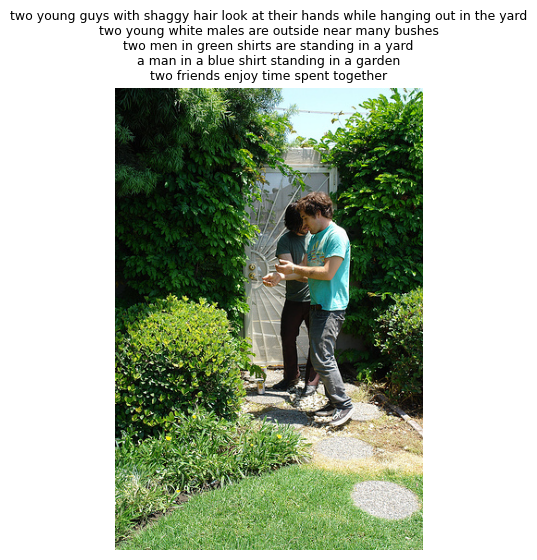


✅ Milestone 2 done.


In [13]:
# ============================================================
# MILESTONE 2 (single cell): EfficientNetB3 features + tf.data pipeline
# ============================================================
import gc, time, shutil
import matplotlib.pyplot as plt

AUTOTUNE = tf.data.AUTOTUNE
os.makedirs(cfg.FEATURE_DIR, exist_ok=True)

# ---------------- 1) Global image index (row i of the feature file = image i) ----------------
all_images = sorted(set(train_df["image"]) | set(val_df["image"]) | set(test_df["image"]))
img2idx = {name: i for i, name in enumerate(all_images)}
print(f"Unique images to encode: {len(all_images)}")

# ---------------- 2) CNN encoder: EfficientNetB3 -> spatial grid tokens ----------------
def build_cnn_encoder(image_size: int) -> keras.Model:
    """Frozen EfficientNetB3 returning (batch, H*W, C) grid features.
    Keras EfficientNet normalizes internally, so inputs are raw [0, 255] pixels."""
    base = keras.applications.EfficientNetB3(
        include_top=False, weights="imagenet", input_shape=(image_size, image_size, 3)
    )
    base.trainable = False
    h, w, c = base.output_shape[1:]
    inputs = keras.Input(shape=(image_size, image_size, 3), name="image")
    x = base(inputs, training=False)
    x = keras.layers.Reshape((h * w, c), name="grid_tokens")(x)
    return keras.Model(inputs, x, name="efficientnetb3_encoder")


def load_image(path: tf.Tensor, image_size: int) -> tf.Tensor:
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (image_size, image_size))     # float32 in [0, 255]
    return img

# ---------------- 3) One-time feature extraction to a disk-backed memmap ----------------
def extract_features(image_names, image_dir, out_path, image_size, batch_size):
    names_path = out_path.replace(".npy", "_images.json")
    meta_path = out_path.replace(".npy", "_meta.json")

    # Resume / reuse: skip extraction if a complete, matching file already exists
    if os.path.exists(meta_path) and os.path.exists(names_path):
        with open(meta_path) as f:
            meta = json.load(f)
        with open(names_path) as f:
            saved_names = json.load(f)
        if meta.get("complete") and saved_names == list(image_names) and meta["image_size"] == image_size:
            print(f"✔ Reusing cached features: {out_path} {tuple(meta['shape'])}")
            return np.load(out_path, mmap_mode="r")

    encoder = build_cnn_encoder(image_size)
    num_tokens, feat_dim = encoder.output_shape[1:]
    n = len(image_names)

    required = n * num_tokens * feat_dim * np.dtype(np.float16).itemsize
    free = shutil.disk_usage(os.path.dirname(out_path)).free
    print(f"Feature file: {n} x {num_tokens} x {feat_dim} (float16) = {required / 1e9:.2f} GB "
          f"| free disk: {free / 1e9:.2f} GB")
    if required > 0.95 * free:
        raise OSError("Not enough disk space for features. Change cfg.FEATURE_DIR.")

    feats = np.lib.format.open_memmap(out_path, mode="w+", dtype=np.float16,
                                      shape=(n, num_tokens, feat_dim))
    paths = [os.path.join(image_dir, name) for name in image_names]
    ds = (tf.data.Dataset.from_tensor_slices(paths)
          .map(lambda p: load_image(p, image_size), num_parallel_calls=AUTOTUNE)
          .batch(batch_size)
          .prefetch(AUTOTUNE))

    @tf.function
    def encode(batch):
        return encoder(batch, training=False)

    start, t0 = 0, time.time()
    total_batches = int(np.ceil(n / batch_size))
    for step, batch in enumerate(ds, 1):
        out = encode(batch).numpy().astype(np.float16)
        feats[start:start + len(out)] = out
        start += len(out)
        if step % 50 == 0 or step == total_batches:
            rate = start / (time.time() - t0)
            print(f"  [{step}/{total_batches}] {start}/{n} images | {rate:.0f} img/s | "
                  f"ETA {(n - start) / rate:.0f}s")

    feats.flush()
    del feats
    with open(names_path, "w") as f:
        json.dump(list(image_names), f)
    with open(meta_path, "w") as f:
        json.dump({"complete": True, "dataset": cfg.DATASET, "image_size": image_size,
                   "shape": [n, num_tokens, feat_dim]}, f)

    # Free GPU memory used by the encoder before training starts
    del encoder
    keras.backend.clear_session()
    gc.collect()
    print(f"✔ Extraction finished in {time.time() - t0:.0f}s")
    return np.load(out_path, mmap_mode="r")


feature_path = os.path.join(cfg.FEATURE_DIR, f"{cfg.DATASET}_effb3_{cfg.IMAGE_SIZE}.npy")
features = extract_features(all_images, cfg.IMAGE_DIR, feature_path,
                            cfg.IMAGE_SIZE, cfg.EXTRACT_BATCH_SIZE)
NUM_IMG_TOKENS, FEAT_DIM = features.shape[1:]
print(f"Features (memmap): {features.shape}, dtype={features.dtype}")

# ---------------- 4) tf.data pipeline: (features, dec_in) -> target ----------------
def make_dataset(df, seqs, features, batch_size, shuffle, seed=cfg.SEED):
    img_idx = df["image"].map(img2idx).to_numpy(np.int32)
    num_tokens, feat_dim = features.shape[1:]

    def gather_features(idx):
        return features[idx]                                 # reads only this batch from disk

    def load_batch(idx, seq):
        feats = tf.numpy_function(gather_features, [idx], tf.float16)
        feats = tf.cast(feats, tf.float32)
        feats.set_shape([None, num_tokens, feat_dim])
        dec_in, target = seq[:, :-1], seq[:, 1:]             # teacher forcing shift
        return (feats, dec_in), target

    ds = tf.data.Dataset.from_tensor_slices((img_idx, seqs))
    if shuffle:
        ds = ds.shuffle(len(img_idx), seed=seed, reshuffle_each_iteration=True)
    ds = (ds.batch(batch_size, drop_remainder=shuffle)
            .map(load_batch, num_parallel_calls=AUTOTUNE)
            .prefetch(AUTOTUNE))
    return ds


train_ds = make_dataset(train_df, train_seqs, features, cfg.BATCH_SIZE, shuffle=True)
val_ds = make_dataset(val_df, val_seqs, features, cfg.BATCH_SIZE, shuffle=False)
print(f"Batches/epoch -> train: {len(train_df) // cfg.BATCH_SIZE}, "
      f"val: {int(np.ceil(len(val_df) / cfg.BATCH_SIZE))}")

# ---------------- 5) Sanity checks ----------------
(f_batch, din_batch), tgt_batch = next(iter(train_ds))
print(f"\nfeatures: {f_batch.shape} {f_batch.dtype}")
print(f"dec_in  : {din_batch.shape} {din_batch.dtype}")
print(f"target  : {tgt_batch.shape} {tgt_batch.dtype}")
print("dec_in[0] :", vocab.decode(din_batch[0].numpy()), "| first id =", int(din_batch[0, 0]))
print("target[0] :", vocab.decode(tgt_batch[0].numpy()))
assert int(din_batch[0, 0]) == vocab.start_id
assert np.array_equal(din_batch[0, 1:].numpy(), tgt_batch[0, :-1].numpy())
assert np.isfinite(f_batch.numpy()).all(), "NaN/Inf in features"

# Throughput benchmark (training should not be data-bound)
t0 = time.time()
for _ in train_ds.take(50):
    pass
print(f"Pipeline speed: {50 / (time.time() - t0):.1f} batches/s")

# Visual check: one image with its reference captions
sample_img = train_df["image"].iloc[0]
plt.figure(figsize=(6, 6))
plt.imshow(plt.imread(os.path.join(cfg.IMAGE_DIR, sample_img)))
plt.axis("off")
plt.title("\n".join(train_df.loc[train_df["image"] == sample_img, "clean"].tolist()[:5]), fontsize=9)
plt.show()

print("\n✅ Milestone 2 done.")

In [14]:
os.makedirs(os.path.join(cfg.WORK_DIR, "src"), exist_ok=True)
open(os.path.join(cfg.WORK_DIR, "src", "__init__.py"), "a").close()
print("src/ ready")

src/ ready


In [15]:
%%writefile /kaggle/working/src/model.py
"""
src/model.py
EfficientNetB3 (CNN encoder) + Transformer decoder for image captioning.
Backend: TensorFlow with Keras 3.
"""
import numpy as np
import keras
from keras import layers, ops


# ============================================================
# CNN encoder (frozen EfficientNetB3 -> spatial grid tokens)
# ============================================================
def build_cnn_encoder(image_size: int = 300) -> keras.Model:
    """Return a frozen EfficientNetB3 producing (batch, H*W, C) grid features.
    Keras EfficientNet normalizes internally, so inputs are raw [0, 255] pixels."""
    base = keras.applications.EfficientNetB3(
        include_top=False, weights="imagenet", input_shape=(image_size, image_size, 3)
    )
    base.trainable = False
    h, w, c = base.output_shape[1:]
    inputs = keras.Input(shape=(image_size, image_size, 3), name="image")
    x = base(inputs, training=False)
    x = layers.Reshape((h * w, c), name="grid_tokens")(x)
    return keras.Model(inputs, x, name="efficientnetb3_encoder")


def sinusoidal_position_encoding(max_len: int, dim: int) -> np.ndarray:
    """Classic 'Attention Is All You Need' sin/cos positional encoding."""
    positions = np.arange(max_len)[:, None]
    dims = np.arange(dim)[None, :]
    angles = positions / np.power(10000.0, (2 * (dims // 2)) / dim)
    pe = np.zeros((max_len, dim), dtype=np.float32)
    pe[:, 0::2] = np.sin(angles[:, 0::2])
    pe[:, 1::2] = np.cos(angles[:, 1::2])
    return pe


# ============================================================
# Building blocks
# ============================================================
@keras.saving.register_keras_serializable(package="captioner")
class FeedForward(layers.Layer):
    def __init__(self, embed_dim, ff_dim, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim, self.ff_dim, self.dropout_rate = embed_dim, ff_dim, dropout
        self.fc1 = layers.Dense(ff_dim, activation="gelu")
        self.fc2 = layers.Dense(embed_dim)
        self.drop = layers.Dropout(dropout)

    def call(self, x, training=None):
        return self.fc2(self.drop(self.fc1(x), training=training))

    def get_config(self):
        return {**super().get_config(), "embed_dim": self.embed_dim,
                "ff_dim": self.ff_dim, "dropout": self.dropout_rate}


@keras.saving.register_keras_serializable(package="captioner")
class TransformerEncoderBlock(layers.Layer):
    """Pre-LN self-attention block over image grid tokens."""

    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim, self.num_heads = embed_dim, num_heads
        self.ff_dim, self.dropout_rate = ff_dim, dropout
        self.ln1 = layers.LayerNormalization(epsilon=1e-6)
        self.attn = layers.MultiHeadAttention(num_heads, key_dim=embed_dim // num_heads,
                                              dropout=dropout)
        self.ln2 = layers.LayerNormalization(epsilon=1e-6)
        self.ffn = FeedForward(embed_dim, ff_dim, dropout)
        self.drop1 = layers.Dropout(dropout)
        self.drop2 = layers.Dropout(dropout)

    def call(self, x, training=None):
        h = self.ln1(x)
        x = x + self.drop1(self.attn(h, h, training=training), training=training)
        x = x + self.drop2(self.ffn(self.ln2(x), training=training), training=training)
        return x

    def get_config(self):
        return {**super().get_config(), "embed_dim": self.embed_dim, "num_heads": self.num_heads,
                "ff_dim": self.ff_dim, "dropout": self.dropout_rate}


@keras.saving.register_keras_serializable(package="captioner")
class TransformerDecoderBlock(layers.Layer):
    """Pre-LN decoder block: causal self-attention -> cross-attention -> FFN."""

    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim, self.num_heads = embed_dim, num_heads
        self.ff_dim, self.dropout_rate = ff_dim, dropout
        key_dim = embed_dim // num_heads
        self.ln1 = layers.LayerNormalization(epsilon=1e-6)
        self.self_attn = layers.MultiHeadAttention(num_heads, key_dim=key_dim, dropout=dropout)
        self.ln2 = layers.LayerNormalization(epsilon=1e-6)
        self.cross_attn = layers.MultiHeadAttention(num_heads, key_dim=key_dim, dropout=dropout)
        self.ln3 = layers.LayerNormalization(epsilon=1e-6)
        self.ffn = FeedForward(embed_dim, ff_dim, dropout)
        self.drop1 = layers.Dropout(dropout)
        self.drop2 = layers.Dropout(dropout)
        self.drop3 = layers.Dropout(dropout)

    def call(self, x, enc_out, training=None):
        # 1) Masked self-attention: each position sees only earlier tokens
        h = self.ln1(x)
        x = x + self.drop1(self.self_attn(h, h, use_causal_mask=True, training=training),
                           training=training)
        # 2) Cross-attention: text queries attend over image grid tokens
        h = self.ln2(x)
        x = x + self.drop2(self.cross_attn(h, enc_out, training=training), training=training)
        # 3) Position-wise feed-forward
        x = x + self.drop3(self.ffn(self.ln3(x), training=training), training=training)
        return x

    def get_config(self):
        return {**super().get_config(), "embed_dim": self.embed_dim, "num_heads": self.num_heads,
                "ff_dim": self.ff_dim, "dropout": self.dropout_rate}


# ============================================================
# Image encoder head & caption decoder
# ============================================================
@keras.saving.register_keras_serializable(package="captioner")
class ImageEncoder(layers.Layer):
    """Projects CNN grid features to embed_dim, adds learned 2D position, refines with self-attention."""

    def __init__(self, num_tokens, embed_dim, num_heads, ff_dim, num_layers=1, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.num_tokens, self.embed_dim, self.num_heads = num_tokens, embed_dim, num_heads
        self.ff_dim, self.num_layers, self.dropout_rate = ff_dim, num_layers, dropout
        self.proj = layers.Dense(embed_dim)
        self.proj_ln = layers.LayerNormalization(epsilon=1e-6)
        self.pos_emb = layers.Embedding(num_tokens, embed_dim)
        self.drop = layers.Dropout(dropout)
        self.blocks = [TransformerEncoderBlock(embed_dim, num_heads, ff_dim, dropout)
                       for _ in range(num_layers)]
        self.final_ln = layers.LayerNormalization(epsilon=1e-6)

    def call(self, x, training=None):
        x = self.proj_ln(self.proj(x))
        x = x + ops.expand_dims(self.pos_emb(ops.arange(self.num_tokens)), 0)
        x = self.drop(x, training=training)
        for block in self.blocks:
            x = block(x, training=training)
        return self.final_ln(x)

    def get_config(self):
        return {**super().get_config(), "num_tokens": self.num_tokens, "embed_dim": self.embed_dim,
                "num_heads": self.num_heads, "ff_dim": self.ff_dim,
                "num_layers": self.num_layers, "dropout": self.dropout_rate}


@keras.saving.register_keras_serializable(package="captioner")
class CaptionDecoder(layers.Layer):
    """Token embedding + sinusoidal positional encoding + N decoder blocks + LM head."""

    def __init__(self, vocab_size, max_len, embed_dim, num_heads, ff_dim,
                 num_layers=3, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.vocab_size, self.max_len, self.embed_dim = vocab_size, max_len, embed_dim
        self.num_heads, self.ff_dim = num_heads, ff_dim
        self.num_layers, self.dropout_rate = num_layers, dropout
        self.token_emb = layers.Embedding(vocab_size, embed_dim)
        self.pos_encoding = ops.convert_to_tensor(sinusoidal_position_encoding(max_len, embed_dim))
        self.scale = float(np.sqrt(embed_dim))
        self.drop = layers.Dropout(dropout)
        self.blocks = [TransformerDecoderBlock(embed_dim, num_heads, ff_dim, dropout)
                       for _ in range(num_layers)]
        self.final_ln = layers.LayerNormalization(epsilon=1e-6)
        self.lm_head = layers.Dense(vocab_size, name="lm_head")

    def call(self, tokens, enc_out, training=None):
        seq_len = ops.shape(tokens)[1]
        x = self.token_emb(tokens) * self.scale
        x = x + self.pos_encoding[None, :seq_len, :]
        x = self.drop(x, training=training)
        for block in self.blocks:
            x = block(x, enc_out, training=training)
        return self.lm_head(self.final_ln(x))          # logits: (batch, seq_len, vocab_size)

    def get_config(self):
        return {**super().get_config(), "vocab_size": self.vocab_size, "max_len": self.max_len,
                "embed_dim": self.embed_dim, "num_heads": self.num_heads, "ff_dim": self.ff_dim,
                "num_layers": self.num_layers, "dropout": self.dropout_rate}


# ============================================================
# Model factory: training model + shared-weight encoder/decoder for fast inference
# ============================================================
def build_caption_model(vocab_size, max_len, num_img_tokens=100, feat_dim=1536,
                        embed_dim=512, num_heads=8, ff_dim=2048,
                        num_decoder_layers=3, num_encoder_layers=1, dropout=0.3):
    image_encoder = ImageEncoder(num_img_tokens, embed_dim, num_heads, ff_dim,
                                 num_encoder_layers, dropout, name="image_encoder")
    decoder = CaptionDecoder(vocab_size, max_len, embed_dim, num_heads, ff_dim,
                             num_decoder_layers, dropout, name="caption_decoder")

    # Training graph: (features, tokens) -> logits
    feats_in = keras.Input(shape=(num_img_tokens, feat_dim), name="image_features")
    tokens_in = keras.Input(shape=(None,), dtype="int32", name="decoder_tokens")
    enc_out = image_encoder(feats_in)
    logits = decoder(tokens_in, enc_out)
    train_model = keras.Model([feats_in, tokens_in], logits, name="image_captioner")

    # Inference graphs (same layer objects -> same weights)
    encoder_model = keras.Model(feats_in, enc_out, name="captioner_encoder")
    enc_in = keras.Input(shape=(num_img_tokens, embed_dim), name="encoded_image")
    step_tokens_in = keras.Input(shape=(None,), dtype="int32", name="decoder_tokens_step")
    decoder_model = keras.Model([enc_in, step_tokens_in], decoder(step_tokens_in, enc_in),
                                name="captioner_decoder")
    return train_model, encoder_model, decoder_model


# ============================================================
# Masked loss & metric (ignore <pad> positions)
# ============================================================
def make_masked_loss(vocab_size: int, pad_id: int = 0, label_smoothing: float = 0.1):
    def masked_loss(y_true, y_pred):
        y_true = ops.cast(y_true, "int32")
        mask = ops.cast(ops.not_equal(y_true, pad_id), y_pred.dtype)
        one_hot = ops.one_hot(y_true, vocab_size)
        loss = keras.losses.categorical_crossentropy(
            one_hot, y_pred, from_logits=True, label_smoothing=label_smoothing
        )                                                   # (batch, seq_len)
        return ops.sum(loss * mask) / ops.maximum(ops.sum(mask), 1.0)
    return masked_loss


def make_masked_accuracy(pad_id: int = 0):
    def masked_accuracy(y_true, y_pred):
        y_true = ops.cast(y_true, "int32")
        y_hat = ops.cast(ops.argmax(y_pred, axis=-1), "int32")
        mask = ops.not_equal(y_true, pad_id)
        correct = ops.logical_and(ops.equal(y_true, y_hat), mask)
        return ops.sum(ops.cast(correct, "float32")) / ops.maximum(
            ops.sum(ops.cast(mask, "float32")), 1.0)
    return masked_accuracy

Writing /kaggle/working/src/model.py


Model: "image_captioner"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_features      │ (None, 100, 1536) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_tokens      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_encoder       │ (None, 100, 512)  │  3,992,576 │ image_features[0… │
│ (ImageEncoder)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ caption_decoder     │ (None, None,      │ 20,185,820 │ decoder_tokens[0… │
│ (CaptionDecoder)    │ 7388)             │            │ image_encoder[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,178,396 (92.23 MB)

 Trainable params: 24,178,396 (92.23 MB)

 Non-trainable params: 0 (0.00 B)

steps/epoch=2326 | total=46520 | warmup=2326


/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis 3 of a tensor of shape (1, 8, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


Smoke test (untrained): entertainment speaker utensils mustang pictured thatched button hole far dice kickboxers screens kickboxers screens kickboxers rain bending helmeted pointy folded bring bikers bring pong bring pong bring
Epoch 1/20
2326/2326 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - loss: 6.0574 - masked_accuracy: 0.2129
Epoch 1: val_loss improved from None to 4.09651, saving model to /kaggle/working/saved_models/flickr30k_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/saved_models/flickr30k_best.weights.h5

--- Sample captions after epoch 1 ---
PRED: a man in a red shirt is holding a red and a red hat
REF : the man with pierced ears is wearing glasses and an orange hat

PRED: a man in a black shirt is sitting at a table with a table
REF : a man with black hair sits in a restaurant with a glass of beer

PRED: a man in a black shirt is walking down a street
REF : a person in tan pants is inside a silver mobile object while people watch

2326/2326 ━━━━━━━━━━━━━━━━━━

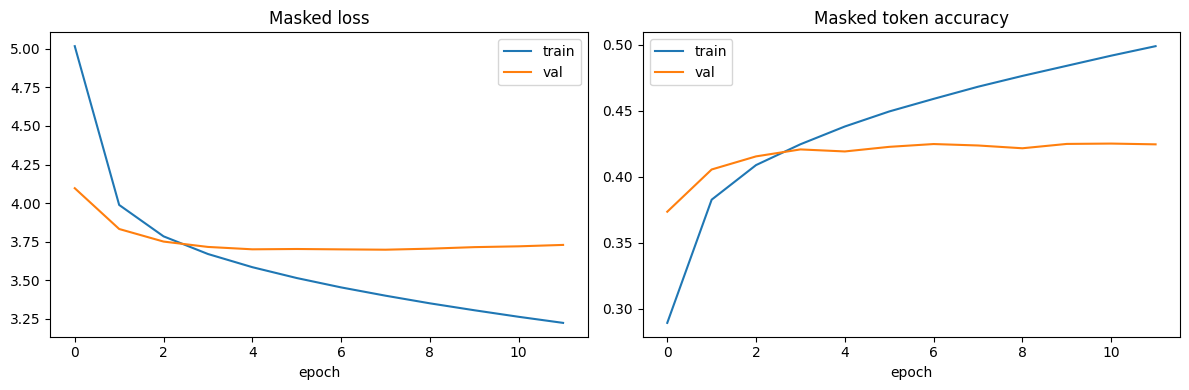


✅ Milestone 3 done. Best weights: /kaggle/working/saved_models/flickr30k_best.weights.h5


In [16]:
# ============================================================
# MILESTONE 3: Build model, compile with AdamW, train
# ============================================================
import sys, importlib
sys.path.insert(0, cfg.WORK_DIR)
import src.model as model_lib
importlib.reload(model_lib)

set_seed(cfg.SEED)

# ---------------- 1) Architecture (saved for inference / API) ----------------
ARCH = dict(
    vocab_size=len(vocab), max_len=cfg.MAX_LEN,
    num_img_tokens=int(NUM_IMG_TOKENS), feat_dim=int(FEAT_DIM),
    embed_dim=cfg.EMBED_DIM, num_heads=cfg.NUM_HEADS, ff_dim=cfg.FF_DIM,
    num_decoder_layers=cfg.NUM_DECODER_LAYERS, num_encoder_layers=1, dropout=cfg.DROPOUT,
)
train_model, encoder_model, decoder_model = model_lib.build_caption_model(**ARCH)
train_model.summary()

with open(os.path.join(cfg.SAVE_DIR, "model_config.json"), "w") as f:
    json.dump({**ARCH, "image_size": cfg.IMAGE_SIZE, "dataset": cfg.DATASET}, f, indent=2)

# ---------------- 2) AdamW + warmup + cosine decay ----------------
steps_per_epoch = len(train_df) // cfg.BATCH_SIZE
total_steps = steps_per_epoch * cfg.EPOCHS
warmup_steps = max(1, int(0.05 * total_steps))

lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0,
    decay_steps=total_steps - warmup_steps,
    alpha=0.05,                                  # final LR = 5% of peak
    warmup_target=cfg.LEARNING_RATE,
    warmup_steps=warmup_steps,
)
optimizer = keras.optimizers.AdamW(
    learning_rate=lr_schedule, weight_decay=cfg.WEIGHT_DECAY,
    beta_1=0.9, beta_2=0.98, epsilon=1e-9, clipnorm=1.0,
)
optimizer.exclude_from_weight_decay(var_names=["bias", "gamma", "beta"])   # no decay on bias / LayerNorm

train_model.compile(
    optimizer=optimizer,
    loss=model_lib.make_masked_loss(len(vocab), pad_id=vocab.pad_id, label_smoothing=0.1),
    metrics=[model_lib.make_masked_accuracy(pad_id=vocab.pad_id)],
)
print(f"steps/epoch={steps_per_epoch} | total={total_steps} | warmup={warmup_steps}")

# ---------------- 3) Greedy decoding for live monitoring (Beam Search comes in Milestone 4) ----------------

def greedy_decode(image_feature: np.ndarray) -> str:
    feat = tf.convert_to_tensor(image_feature[None], dtype=tf.float32)
    enc = encoder_model(feat, training=False)
    tokens = [vocab.start_id]
    for _ in range(cfg.MAX_LEN - 1):
        tok = tf.convert_to_tensor([tokens], dtype=tf.int32)          # tensor, not numpy
        logits = decoder_model([enc, tok], training=False)
        next_id = int(tf.argmax(logits[0, -1]).numpy())
        if next_id == vocab.end_id:
            break
        tokens.append(next_id)
    return vocab.decode(tokens)


class SampleCaptionCallback(keras.callbacks.Callback):
    """Print greedy captions for a few fixed validation images after each epoch."""

    def __init__(self, image_names):
        super().__init__()
        self.image_names = image_names

    def on_epoch_end(self, epoch, logs=None):
        print(f"\n--- Sample captions after epoch {epoch + 1} ---")
        for name in self.image_names:
            pred = greedy_decode(np.asarray(features[img2idx[name]]))
            ref = val_df.loc[val_df["image"] == name, "clean"].iloc[0]
            print(f"PRED: {pred}\nREF : {ref}\n")


sample_val_images = val_df["image"].drop_duplicates().iloc[:3].tolist()
best_weights_path = os.path.join(cfg.SAVE_DIR, f"{cfg.DATASET}_best.weights.h5")

callbacks = [
    keras.callbacks.ModelCheckpoint(best_weights_path, monitor="val_loss",
                                    save_best_only=True, save_weights_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=cfg.EARLY_STOPPING_PATIENCE,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.CSVLogger(os.path.join(cfg.SAVE_DIR, f"{cfg.DATASET}_history.csv")),
    SampleCaptionCallback(sample_val_images),
]
# Smoke test: make sure decoding works BEFORE spending time on training
print("Smoke test (untrained):", greedy_decode(np.asarray(features[img2idx[sample_val_images[0]]])))

# ---------------- 4) Train ----------------
history = train_model.fit(train_ds, validation_data=val_ds,
                          epochs=cfg.EPOCHS, callbacks=callbacks, verbose=1)

# ---------------- 5) Learning curves ----------------
hist = history.history
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["loss"], label="train"); axes[0].plot(hist["val_loss"], label="val")
axes[0].set_title("Masked loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(hist["masked_accuracy"], label="train"); axes[1].plot(hist["val_masked_accuracy"], label="val")
axes[1].set_title("Masked token accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(cfg.SAVE_DIR, f"{cfg.DATASET}_curves.png"), dpi=120)
plt.show()

print(f"\n✅ Milestone 3 done. Best weights: {best_weights_path}")

In [17]:
%%writefile /kaggle/working/src/inference.py
"""
src/inference.py
Vocabulary, image preprocessing and Beam Search caption generation.
Framework-light: only needs TensorFlow/Keras + the saved artifacts:
    saved_models/vocab.json, saved_models/model_config.json, saved_models/caption_model.weights.h5
"""
import json
import os
from typing import Dict, List, Sequence, Union

import numpy as np
import tensorflow as tf

from .model import build_caption_model, build_cnn_encoder

ImageInput = Union[bytes, bytearray, str, np.ndarray]


# ============================================================
# Vocabulary (identical logic to training)
# ============================================================
class Vocabulary:
    PAD, START, END, UNK = "<pad>", "<start>", "<end>", "<unk>"
    SPECIAL_TOKENS = [PAD, START, END, UNK]

    def __init__(self, idx2word: List[str], max_len: int):
        self.idx2word, self.max_len = idx2word, max_len
        self.word2idx = {w: i for i, w in enumerate(idx2word)}
        self.pad_id, self.start_id = self.word2idx[self.PAD], self.word2idx[self.START]
        self.end_id, self.unk_id = self.word2idx[self.END], self.word2idx[self.UNK]

    def __len__(self) -> int:
        return len(self.idx2word)

    def encode(self, caption: str) -> List[int]:
        ids = [self.word2idx.get(w, self.unk_id) for w in caption.split()]
        ids = [self.start_id] + ids[: self.max_len - 2] + [self.end_id]
        return ids + [self.pad_id] * (self.max_len - len(ids))

    def decode(self, ids: Sequence[int]) -> str:
        words = []
        for i in map(int, ids):
            if i == self.end_id:
                break
            if i not in (self.pad_id, self.start_id):
                words.append(self.idx2word[i])
        return " ".join(words)

    def save(self, path: str) -> None:
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"idx2word": self.idx2word, "max_len": self.max_len}, f, indent=2)

    @classmethod
    def load(cls, path: str) -> "Vocabulary":
        with open(path, encoding="utf-8") as f:
            data = json.load(f)
        return cls(data["idx2word"], data["max_len"])


# ============================================================
# Caption generator
# ============================================================
class CaptionGenerator:
    """Load artifacts once, then caption images (raw bytes / path / array) or precomputed features."""

    def __init__(self, model_dir: str, weights_file: str = "caption_model.weights.h5",
                 load_cnn: bool = True):
        with open(os.path.join(model_dir, "model_config.json")) as f:
            arch = json.load(f)
        self.image_size = int(arch.pop("image_size"))
        self.trained_on = arch.pop("dataset", "unknown")
        self.arch = arch

        self.vocab = Vocabulary.load(os.path.join(model_dir, "vocab.json"))
        if len(self.vocab) != arch["vocab_size"]:
            raise ValueError("vocab.json does not match model_config.json (vocab_size mismatch).")

        self.train_model, self.encoder_model, self.decoder_model = build_caption_model(**arch)
        self.train_model.load_weights(os.path.join(model_dir, weights_file))

        n_tok, feat_dim, emb = arch["num_img_tokens"], arch["feat_dim"], arch["embed_dim"]
        self._encode_step = tf.function(
            lambda f: self.encoder_model(f, training=False),
            input_signature=[tf.TensorSpec([None, n_tok, feat_dim], tf.float32)],
        )
        self._decode_step = tf.function(
            lambda enc, tok: self.decoder_model([enc, tok], training=False),
            input_signature=[tf.TensorSpec([None, n_tok, emb], tf.float32),
                             tf.TensorSpec([None, None], tf.int32)],
        )

        self.cnn = None
        if load_cnn:
            self.cnn = build_cnn_encoder(self.image_size)
            self._cnn_step = tf.function(
                lambda x: self.cnn(x, training=False),
                input_signature=[tf.TensorSpec([None, self.image_size, self.image_size, 3], tf.float32)],
            )

        v = self.vocab
        self.banned_ids = [v.pad_id, v.start_id, v.unk_id]

    # ---------------- Preprocessing ----------------
    def preprocess(self, image: ImageInput) -> tf.Tensor:
        """Return a (1, S, S, 3) float32 tensor in [0, 255] (EfficientNet normalizes internally)."""
        if isinstance(image, (bytes, bytearray)):
            img = tf.io.decode_image(bytes(image), channels=3, expand_animations=False)
        elif isinstance(image, str):
            img = tf.io.decode_image(tf.io.read_file(image), channels=3, expand_animations=False)
        elif isinstance(image, np.ndarray):
            img = tf.convert_to_tensor(image)
            if img.shape.rank == 2:
                img = tf.stack([img] * 3, axis=-1)
            img = img[..., :3]
        else:
            raise TypeError(f"Unsupported image type: {type(image)}")
        img = tf.image.resize(tf.cast(img, tf.float32), (self.image_size, self.image_size))
        return img[None]

    def extract_features(self, image: ImageInput) -> tf.Tensor:
        if self.cnn is None:
            raise RuntimeError("CNN encoder not loaded. Use CaptionGenerator(..., load_cnn=True).")
        feats = self._cnn_step(self.preprocess(image))
        return tf.cast(tf.cast(feats, tf.float16), tf.float32)    # match float16 training cache

    # ---------------- Beam Search ----------------
    @staticmethod
    def _length_normalize(log_prob: float, length: int, alpha: float) -> float:
        return log_prob / (max(length, 1) ** alpha)

    @staticmethod
    def _banned_ngram_tokens(seq: List[int], n: int) -> List[int]:
        """Tokens that would complete an n-gram already present in seq."""
        if n <= 0 or len(seq) < n:
            return []
        prefix = tuple(seq[-(n - 1):]) if n > 1 else ()
        return [seq[i + n - 1] for i in range(len(seq) - n + 1)
                if tuple(seq[i:i + n - 1]) == prefix]

    def beam_search(self, enc: tf.Tensor, beam_width: int = 3, max_len: int = None,
                    length_alpha: float = 0.7, no_repeat_ngram_size: int = 3) -> List[Dict]:
        v = self.vocab
        max_len = max_len or v.max_len
        beams = [([v.start_id], 0.0)]           # (token sequence, cumulative log-prob)
        finished = []

        for _ in range(max_len - 1):
            tokens = tf.constant([seq for seq, _ in beams], dtype=tf.int32)
            enc_rep = tf.repeat(enc, repeats=len(beams), axis=0)
            logits = self._decode_step(enc_rep, tokens)[:, -1, :]
            log_probs = tf.nn.log_softmax(logits, axis=-1).numpy()
            log_probs[:, self.banned_ids] = -np.inf

            candidates = []
            for i, (seq, score) in enumerate(beams):
                lp = log_probs[i]
                for tok in self._banned_ngram_tokens(seq, no_repeat_ngram_size):
                    lp[tok] = -np.inf
                k = min(2 * beam_width, lp.shape[0])
                for tok in np.argpartition(-lp, k - 1)[:k]:
                    if np.isfinite(lp[tok]):
                        candidates.append((seq + [int(tok)], score + float(lp[tok])))

            candidates.sort(key=lambda c: c[1], reverse=True)
            beams = []
            for seq, score in candidates:
                if seq[-1] == v.end_id:
                    finished.append((seq, self._length_normalize(score, len(seq) - 1, length_alpha)))
                else:
                    beams.append((seq, score))
                if len(beams) == beam_width:
                    break
            if not beams or len(finished) >= beam_width:
                break

        if not finished:                         # hit max_len without <end>
            finished = [(seq, self._length_normalize(s, len(seq) - 1, length_alpha)) for seq, s in beams]

        finished.sort(key=lambda c: c[1], reverse=True)
        return [{"caption": v.decode(seq), "score": round(float(s), 4)} for seq, s in finished]

    # ---------------- Public API ----------------
    def caption_from_features(self, features: np.ndarray, beam_width: int = 3, **kwargs) -> List[Dict]:
        feats = np.asarray(features, dtype=np.float32)
        if feats.ndim == 2:
            feats = feats[None]
        enc = self._encode_step(tf.convert_to_tensor(feats))
        return self.beam_search(enc, beam_width=beam_width, **kwargs)

    def caption(self, image: ImageInput, beam_width: int = 3, **kwargs) -> List[Dict]:
        enc = self._encode_step(self.extract_features(image))
        return self.beam_search(enc, beam_width=beam_width, **kwargs)

Writing /kaggle/working/src/inference.py


Generator ready | trained on: flickr30k | vocab: 7388
  beam=1: 250/1000 (28s)
  beam=1: 500/1000 (54s)
  beam=1: 750/1000 (82s)
  beam=1: 1000/1000 (110s)
  beam=3: 250/1000 (33s)
  beam=3: 500/1000 (65s)
  beam=3: 750/1000 (98s)
  beam=3: 1000/1000 (131s)

Test set: 1000 images (flickr30k)
        Greedy  Beam (k=3)
BLEU-1  0.6370      0.6616
BLEU-2  0.4560      0.4802
BLEU-3  0.3151      0.3411
BLEU-4  0.2177      0.2423

End-to-end parity
  cached features: a group of people are standing around a table
  raw image     : a group of people are standing around a table


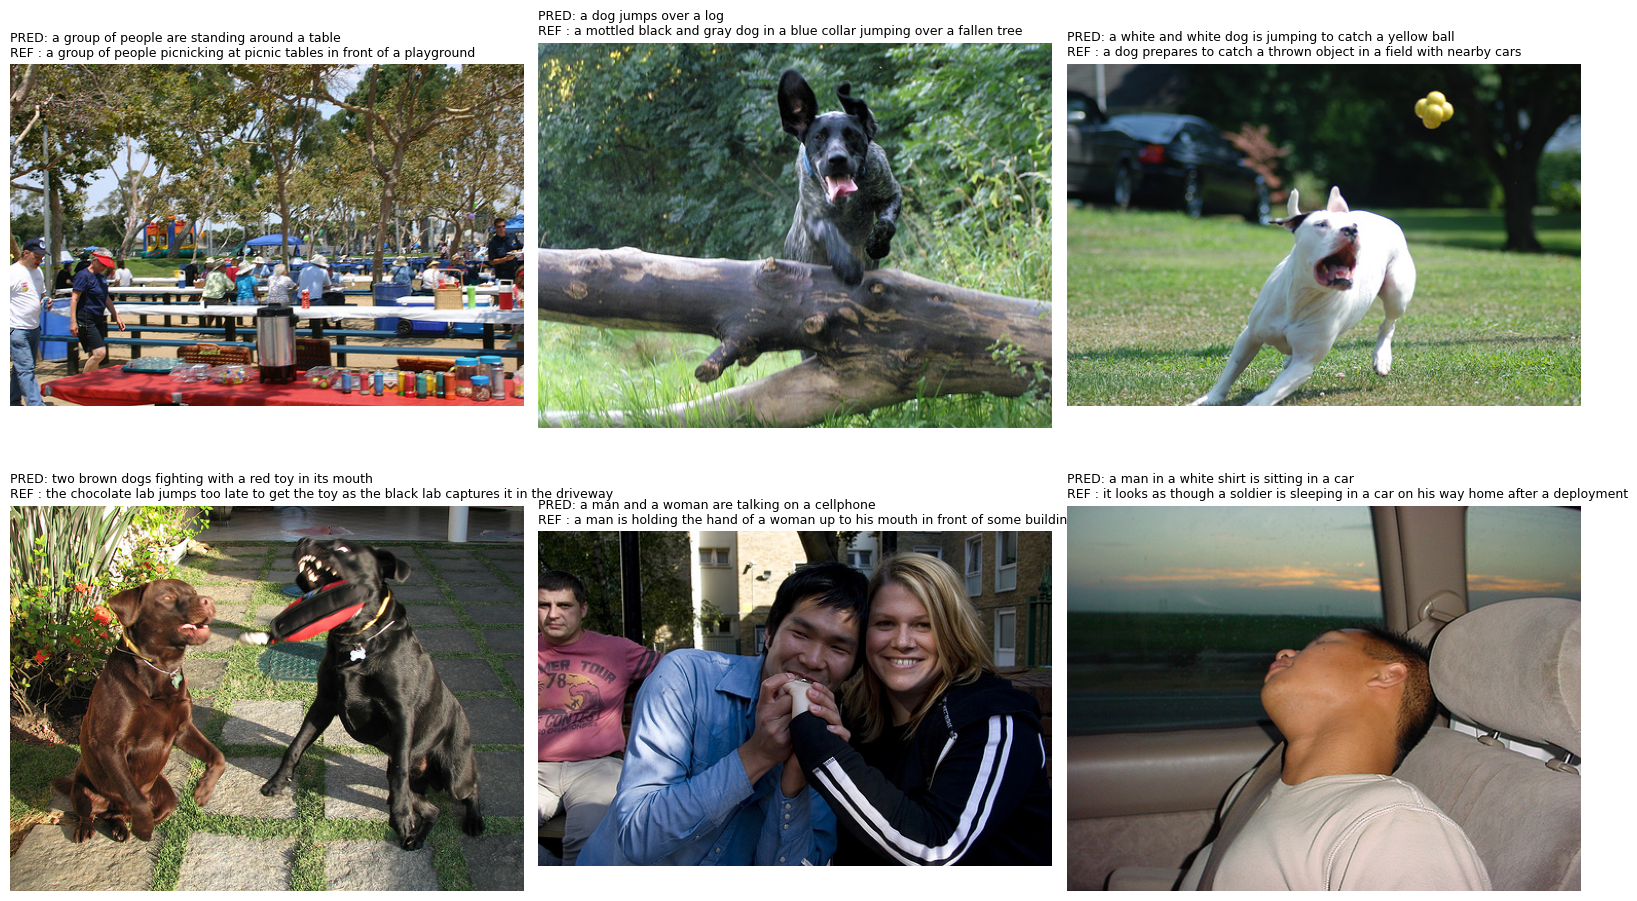


Weights size: 290.5 MB
Artifacts zip: /kaggle/working/image_caption_artifacts_flickr30k.zip (269.4 MB)

✅ Milestone 4 done.


In [18]:
# ============================================================
# MILESTONE 4: Beam Search evaluation, BLEU, artifacts
# ============================================================
import shutil, time, zipfile
from nltk.translate.bleu_score import corpus_bleu
import src.model as model_lib
import src.inference as inf_lib
importlib.reload(model_lib)
importlib.reload(inf_lib)

# ---------------- 1) Finalize weights under a dataset-independent name ----------------
best_weights_path = os.path.join(cfg.SAVE_DIR, f"{cfg.DATASET}_best.weights.h5")
final_weights_path = os.path.join(cfg.SAVE_DIR, "caption_model.weights.h5")
shutil.copy(best_weights_path, final_weights_path)

generator = inf_lib.CaptionGenerator(cfg.SAVE_DIR, load_cnn=True)
print(f"Generator ready | trained on: {generator.trained_on} | vocab: {len(generator.vocab)}")

# ---------------- 2) Evaluate on the held-out TEST set ----------------
test_images = test_df["image"].drop_duplicates().tolist()
references = {img: [c.split() for c in grp["clean"]] for img, grp in test_df.groupby("image")}
refs_list = [references[img] for img in test_images]


def evaluate(beam_width: int):
    hyps, rows, t0 = [], [], time.time()
    for i, img in enumerate(test_images, 1):
        best = generator.caption_from_features(features[img2idx[img]], beam_width=beam_width)[0]
        hyps.append(best["caption"].split())
        rows.append({"image": img, "prediction": best["caption"], "score": best["score"]})
        if i % 250 == 0:
            print(f"  beam={beam_width}: {i}/{len(test_images)} ({time.time() - t0:.0f}s)")
    bleu = {f"BLEU-{n}": round(corpus_bleu(refs_list, hyps, weights=tuple([1 / n] * n)), 4)
            for n in range(1, 5)}
    return bleu, pd.DataFrame(rows)


bleu_greedy, _ = evaluate(beam_width=1)
bleu_beam, preds_df = evaluate(beam_width=cfg.BEAM_WIDTH)

results_table = pd.DataFrame({"Greedy": bleu_greedy, f"Beam (k={cfg.BEAM_WIDTH})": bleu_beam})
print(f"\nTest set: {len(test_images)} images ({cfg.DATASET})")
print(results_table.to_string())

# ---------------- 3) End-to-end check: raw image -> CNN -> caption ----------------
probe = test_images[0]
from_cache = generator.caption_from_features(features[img2idx[probe]], beam_width=cfg.BEAM_WIDTH)[0]["caption"]
from_raw = generator.caption(os.path.join(cfg.IMAGE_DIR, probe), beam_width=cfg.BEAM_WIDTH)[0]["caption"]
print(f"\nEnd-to-end parity\n  cached features: {from_cache}\n  raw image     : {from_raw}")

# ---------------- 4) Qualitative grid ----------------
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, img in zip(axes.ravel(), test_images[:6]):
    pred = preds_df.loc[preds_df["image"] == img, "prediction"].iloc[0]
    ax.imshow(plt.imread(os.path.join(cfg.IMAGE_DIR, img)))
    ax.set_title(f"PRED: {pred}\nREF : {' '.join(references[img][0])}", fontsize=9, loc="left")
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(cfg.SAVE_DIR, f"{cfg.DATASET}_test_samples.png"), dpi=110)
plt.show()

# ---------------- 5) Save results ----------------
preds_df["reference"] = preds_df["image"].map(lambda im: " ".join(references[im][0]))
preds_df.to_csv(os.path.join(cfg.SAVE_DIR, f"{cfg.DATASET}_test_predictions.csv"), index=False)
with open(os.path.join(cfg.SAVE_DIR, f"{cfg.DATASET}_test_results.json"), "w") as f:
    json.dump({"dataset": cfg.DATASET, "num_test_images": len(test_images),
               "beam_width": cfg.BEAM_WIDTH, "greedy": bleu_greedy, "beam": bleu_beam}, f, indent=2)

# ---------------- 6) Package src/ + saved_models/ for download ----------------
zip_path = os.path.join(cfg.WORK_DIR, f"image_caption_artifacts_{cfg.DATASET}.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in ["src", "saved_models"]:
        for root, _, files in os.walk(os.path.join(cfg.WORK_DIR, folder)):
            if "__pycache__" in root:
                continue
            for name in files:
                if name.endswith("_best.weights.h5"):        # duplicate of caption_model.weights.h5
                    continue
                full = os.path.join(root, name)
                zf.write(full, os.path.relpath(full, cfg.WORK_DIR))

print(f"\nWeights size: {os.path.getsize(final_weights_path) / 1e6:.1f} MB")
print(f"Artifacts zip: {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB)")
print("\n✅ Milestone 4 done.")

In [22]:
import os, zipfile
from IPython.display import FileLink, display

WORK_DIR = "/kaggle/working"
print("Files in /kaggle/working:")
for root, _, files in os.walk(WORK_DIR):
    if "__pycache__" in root or "/." in root:
        continue
    for f in files:
        p = os.path.join(root, f)
        print(f"  {os.path.relpath(p, WORK_DIR):55s} {os.path.getsize(p) / 1e6:8.2f} MB")

required = ["saved_models/caption_model.weights.h5", "saved_models/vocab.json",
            "saved_models/model_config.json", "src/model.py", "src/inference.py"]
missing = [r for r in required if not os.path.exists(os.path.join(WORK_DIR, r))]

if missing:
    print("\n❌ Missing:", missing)
    print("Session was reset -> re-run the notebook (see Step 2).")
else:
    zip_path = os.path.join(WORK_DIR, "image_caption_artifacts.zip")
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for folder in ["src", "saved_models"]:
            for root, _, files in os.walk(os.path.join(WORK_DIR, folder)):
                if "__pycache__" in root:
                    continue
                for name in files:
                    if name.endswith("_best.weights.h5"):
                        continue
                    full = os.path.join(root, name)
                    zf.write(full, os.path.relpath(full, WORK_DIR))
    print(f"\n✅ Zip ready: {os.path.getsize(zip_path) / 1e6:.1f} MB")
    display(FileLink("image_caption_artifacts.zip"))     # click this link to download

Files in /kaggle/working:
  image_caption_artifacts.zip                               269.38 MB
  image_caption_artifacts_flickr30k.zip                     269.38 MB
  src/inference.py                                            0.01 MB
  src/__init__.py                                             0.00 MB
  src/model.py                                                0.01 MB
  saved_models/flickr30k_test_results.json                    0.00 MB
  saved_models/model_config.json                              0.00 MB
  saved_models/vocab.json                                     0.11 MB
  saved_models/flickr30k_history.csv                          0.00 MB
  saved_models/flickr30k_curves.png                           0.05 MB
  saved_models/config.json                                    0.00 MB
  saved_models/caption_model.weights.h5                     290.48 MB
  saved_models/flickr30k_best.weights.h5                    290.48 MB
  saved_models/flickr30k_test_predictions.csv                 0.

/kaggle/working/image_caption_artifacts.zip

In [1]:
import tensorflow as tf, keras; print(tf.__version__, keras.__version__)

I0000 00:00:1795665347.278203      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795665366.348519      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


2.21.0 3.13.2
